<a href="https://colab.research.google.com/github/Anjanique-Knight/AjGIS/blob/main/PS3_GIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

For ps2 I used information available on the NJ DCA website to find affordable housing developments in Atlantic County.  As a current resident of Atlantic County, I thought it would be more digestable to focus on one county's municipalities and affordable housing devleopment.  Using the same methods I can replicate several maps of NJ counties and use DCA's housing devleopment lists to plot the developments throughout NJ.  

After simplifying the map to just Southern NJ Counties,. I simplified it down to just Atlantic Counties

After finding this data I updated the Atlantic Housing Development sheet to include cities assocciated with development sites and used Nominatim to convert locations to x/y or Long/Lat points to show on the Atlantic County map.

Once established I used a NJ.gov stats to get population density for Atlantic County municipalities.

Future maps may include average rental unit mixes(# of bedrooms) or average rents against affordable housing developments stats to further establish need.


# Set Up

In [ ]:
#!pip install geopandas

import geopandas as gpd
import zipfile

In [ ]:
! wget -O njCO1.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Counties_3857_2520527434192953465.zip

In [ ]:
zip_ref = zipfile.ZipFile('njCO1.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [ ]:
gdf=gpd.read_file('NJ_Counties_3857.shp')

In [ ]:
gdf.plot()

In [ ]:
import pandas as pd


In [ ]:
gdf.head()

# Isolating South Jersey

In [ ]:
snj_counties=['ATLANTIC', 'CUMBERLAND', 'CAMDEN', 'BURLINGTON', 'CAPE MAY', 'SALEM', 'GLOUCESTER', 'OCEAN']

In [ ]:
from numpy import copy
gdf[gdf['COUNTY'].isin(snj_counties)].copy

In [ ]:
import matplotlib.pyplot as plt

# Filter the GeoDataFrame to keep only the Southern NJ counties
snj_gdf = gdf[gdf['COUNTY'].isin(snj_counties)].copy()

fig, ax = plt.subplots(figsize=(10, 10))
snj_gdf.plot(ax=ax, edgecolor='black', color='lightblue', linewidth=1.2)

plt.title('Map of Southern New Jersey Counties', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

# Isolating Atlantic County

In [ ]:
ATLantic = snj_gdf[snj_gdf['COUNTY'] == 'ATLANTIC'].copy()
fig, ax = plt.subplots(figsize=(10, 10))
ATLantic.plot(ax=ax, edgecolor='black', color='salmon', linewidth=1.5)
plt.title('Map of Atlantic County, NJ', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

In [ ]:
! wget -q -O njMun.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Municipal_Boundaries_3424_-6792731789006169525.zip

In [ ]:
zip_ref = zipfile.ZipFile('njMun.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [ ]:
gdf=gpd.read_file('NJ_Municipal_Boundaries_3424.shp')

In [ ]:
gdf.plot()

In [ ]:
import pandas as pd


In [ ]:
gdf.head()

In [ ]:
# Filter to keep only municipalities in Atlantic County
atlantic_mun_gdf = gdf[gdf['COUNTY'] == 'ATLANTIC'].copy()

# Display the first few rows of the filtered GeoDataFrame
display(atlantic_mun_gdf.head())


In [ ]:
# Filter and plot the municipalities of Atlantic County
import matplotlib.pyplot as plt

# Ensure the filtered GeoDataFrame is defined
atlantic_mun_gdf = gdf[gdf['COUNTY'] == 'ATLANTIC'].copy()

fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='lightgreen', linewidth=0.8)
plt.title('Municipalities of Atlantic County, NJ', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

#Geocoding Atlantic County Affordable Housing

In [ ]:
ATLhome=pd.read_excel('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/atlantic.xlsx')
ATLhome=ATLhome[0:5]
ATLhome

In [ ]:
from geopandas.tools import geocode

In [26]:
# Filter out rows with placeholder street names like 'intentional blank'
valid_homes = ATLhome[~ATLhome['street'].astype(str).str.contains('intentional blank', case=False, na=True)].copy()

# Combine valid street, 'City ', and state into address strings
full_addresses = valid_homes['street'].astype(str) + ', ' + valid_homes['City '].astype(str) + ', NJ'

# Geocode the valid addresses
ATLgeo = geocode(full_addresses, provider='nominatim', user_agent='Aj', timeout=5)
ATLgeo.head()

,geometry,address
3,POINT (-74.51256 39.41702),"Rose Hill Drive, Absecon, Atlantic County, New..."
4,POINT (-74.49304 39.43958),"3, School View Drive, Mi-Place at the Shore, A..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

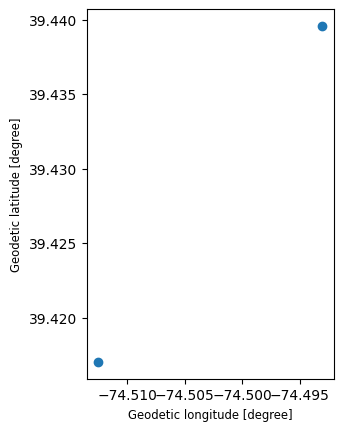

In [27]:
ATLgeo.plot()

In [28]:
import time
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd

# 1. Load the FULL dataset without slicing
ATLhome_full = pd.read_excel('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/atlantic.xlsx')

# 2. Filter out rows with placeholder street names like 'intentional blank'
valid_homes_full = ATLhome_full[
    ~ATLhome_full['street'].astype(str).str.contains('intentional blank', case=False, na=True)
].copy()

# 3. Combine valid street, 'City ', and state into full address strings
valid_homes_full['full_address'] = valid_homes_full['street'].astype(str) + ', ' + valid_homes_full['City '].astype(str) + ', NJ'

# 4. Initialize Nominatim Geocoder and RateLimiter to enforce 1 second per request
geolocator = Nominatim(user_agent="nj_affordable_housing_mapper_aj")
geocode_with_delay = RateLimiter(geolocator.geocode, min_delay_seconds=1.1, return_value_on_exception=None)

# 5. Geocode the addresses
print(f"Geocoding {len(valid_homes_full)} addresses with a rate-limit delay (takes about 1.5 - 2 minutes). Please wait...")
valid_homes_full['location'] = valid_homes_full['full_address'].apply(geocode_with_delay)

# 6. Extract geometry and clean up results
valid_homes_full['point'] = valid_homes_full['location'].apply(lambda loc: Point(loc.longitude, loc.latitude) if loc else None)
valid_homes_full['address_matched'] = valid_homes_full['location'].apply(lambda loc: loc.address if loc else None)

# Drop rows that failed to geocode
final_geocoded = valid_homes_full.dropna(subset=['point']).copy()

# Convert to GeoDataFrame
ATLgeo_full = gpd.GeoDataFrame(final_geocoded, geometry='point', crs="EPSG:4326")

# Configure pandas to show all rows in display
pd.set_option('display.max_rows', None)

# Display the entire geocoded address list (using 'point' as the geometry column name)
display(ATLgeo_full[['street', 'City ', 'address_matched', 'point']])

Geocoding 92 addresses with a rate-limit delay (takes about 1.5 - 2 minutes). Please wait...


,street,City,address_matched,point
3,600 Rose Hill Dr,Absecon,"Rose Hill Drive, Absecon, Atlantic County, New...",POINT (-74.51256 39.41702)
4,3 School View Dr,Absecon,"3, School View Drive, Mi-Place at the Shore, A...",POINT (-74.49304 39.43958)
5,227 N Vermont Av,Atlantic City,"Charles P. Jeffries Tower, 227, North Vermont ...",POINT (-74.41612 39.37123)
6,334 N Tennesee Av,Atlantic City,"South Tennesee Avenue, Midtown, Inlet, Atlanti...",POINT (-74.42594 39.35893)
7,46 N Connecticut Av,Atlantic City,"46, North Connecticut Avenue, Uptown, Inlet, A...",POINT (-74.41922 39.36751)
8,1000 Arctic Av,Atlantic City,"Altman Terrace, 1000, Arctic Avenue, Uptown, I...",POINT (-74.42457 39.36531)
11,1330 Mediterranean Av,Atlantic City,"1330, Mediterranean Avenue, Midtown North, Wes...",POINT (-74.42996 39.36653)
12,732 N Maryland Av,Atlantic City,"732, North Maryland Avenue, Bungalow Park, Inl...",POINT (-74.42764 39.3732)
13,1313 Baltic Av,Atlantic City,"1313, Baltic Avenue, Midtown North, Westside, ...",POINT (-74.42899 39.36544)
14,721 N Atlantic Av,Atlantic City,"Atlantic Avenue, Uptown, Inlet, Atlantic City,...",POINT (-74.41984 39.36545)


In [29]:
ATLgeo_full.head()

,o,seq,ltd,source,notes,proj_no,pro_no_2,Unnamed: 7,development / aka,aka,...,phone_2,website,Unnamed: 35,program,date,seq.1,full_address,location,point,address_matched
3,5,20001,NaN,tax credit,NaN,010109937,NaN,NaN,Clayton Mill Run Apts,5 bldgs; facility id 010109937,...,793-2078,Clayton Mill Run - Conifer Realty LLC (conifer...,NaN,tax credit / MtL,NaT,20001,"600 Rose Hill Dr, Absecon, NJ","(Rose Hill Drive, Absecon, Atlantic County, Ne...",POINT (-74.51256 39.41702),"Rose Hill Drive, Absecon, Atlantic County, New..."
4,6,30005,NaN,HUD,NaN,NJ39RDD1317,NaN,NaN,Visions at Absecon Family & Senior Apts,1 bldg; 24 du,...,NaN,NaN,NaN,NaN,NaT,30005,"3 School View Dr, Absecon, NJ","(3, School View Drive, Mi-Place at the Shore, ...",POINT (-74.49304 39.43958),"3, School View Drive, Mi-Place at the Shore, A..."
5,8,10001,NaN,PHA,NaN,NJ014,NaN,NaN,Atlantic City Housing Authority,NaN,...,344-1107,"Welcome to Atlantic City Housing Authority, NJ...",NaN,Public Housing,2022-01-12,10001,"227 N Vermont Av, Atlantic City, NJ","(Charles P. Jeffries Tower, 227, North Vermont...",POINT (-74.41612 39.37123),"Charles P. Jeffries Tower, 227, North Vermont ..."
6,9,90001,NaN,MtL,NaN,NaN,NaN,NaN,334 N Tennesee Av Apts,NaN,...,348-3188,NaN,NaN,MtL,NaT,90001,"334 N Tennesee Av, Atlantic City, NJ","(South Tennesee Avenue, Midtown, Inlet, Atlant...",POINT (-74.42594 39.35893),"South Tennesee Avenue, Midtown, Inlet, Atlanti..."
7,10,20002,NaN,tax credit,NaN,NJA20123008,LITC #302,NaN,46 N Connecticut Av Apts,NaN,...,233-6942,NaN,NaN,tax credit,NaT,20002,"46 N Connecticut Av, Atlantic City, NJ","(46, North Connecticut Avenue, Uptown, Inlet, ...",POINT (-74.41922 39.36751),"46, North Connecticut Avenue, Uptown, Inlet, A..."


# Plotting Atlantic County Population Density

In [30]:
!wget -q -O ACpop.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/New_Jersey_Population_Density.xlsx

In [31]:
zip_ref = zipfile.ZipFile('ACpop.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [32]:
# Read the downloaded Excel file directly using pandas
pop_df = pd.read_excel('ACpop.zip')
pop_df.head()

,FIPS County,FIPS MCD,AreaName,Land Area (sq mi),Total Population Census 2020,Total Population Estimates 2022,Persons per Sq Mi Census 2020,Persons per Sq Mi Estimates 2022
0,1,100,Absecon city,5.5,9136,9155,1670.7,1674.2
1,1,2080,Atlantic City city,10.8,38501,38561,3578.0,3583.6
2,1,7810,Brigantine city,6.5,7718,7665,1183.3,1175.2
3,1,8680,Buena borough,7.6,4507,4500,595.2,594.2
4,1,8710,Buena Vista township,41.1,7037,7079,171.3,172.3


In [33]:
# Clean up city/municipality names in both DataFrames to ensure they match reliably
pop_df['clean_city'] = pop_df['AreaName'].str.replace(r'\s+(city|township|borough|town)$', '', regex=True, case=False).str.strip().str.lower()
ATLgeo_full['clean_city'] = ATLgeo_full['City '].astype(str).str.strip().str.lower()

# Merge on the cleaned city name column
ATLgeo_full = pd.merge(ATLgeo_full, pop_df, on='clean_city', how='left')
ATLgeo_full.head()

,o,seq,ltd,source,notes,proj_no,pro_no_2,Unnamed: 7,development / aka,aka,...,address_matched,clean_city,FIPS County,FIPS MCD,AreaName,Land Area (sq mi),Total Population Census 2020,Total Population Estimates 2022,Persons per Sq Mi Census 2020,Persons per Sq Mi Estimates 2022
0,5,20001,NaN,tax credit,NaN,010109937,NaN,NaN,Clayton Mill Run Apts,5 bldgs; facility id 010109937,...,"Rose Hill Drive, Absecon, Atlantic County, New...",absecon,1.0,100.0,Absecon city,5.5,9136.0,9155.0,1670.7,1674.2
1,6,30005,NaN,HUD,NaN,NJ39RDD1317,NaN,NaN,Visions at Absecon Family & Senior Apts,1 bldg; 24 du,...,"3, School View Drive, Mi-Place at the Shore, A...",absecon,1.0,100.0,Absecon city,5.5,9136.0,9155.0,1670.7,1674.2
2,8,10001,NaN,PHA,NaN,NJ014,NaN,NaN,Atlantic City Housing Authority,NaN,...,"Charles P. Jeffries Tower, 227, North Vermont ...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6
3,9,90001,NaN,MtL,NaN,NaN,NaN,NaN,334 N Tennesee Av Apts,NaN,...,"South Tennesee Avenue, Midtown, Inlet, Atlanti...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6
4,10,20002,NaN,tax credit,NaN,NJA20123008,LITC #302,NaN,46 N Connecticut Av Apts,NaN,...,"46, North Connecticut Avenue, Uptown, Inlet, A...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6


# Finding Unmatched Municipalities with an Outer Merge and Indicator


In [34]:
# Perform an outer merge with indicator enabled
merge_check = pd.merge(
    ATLgeo_full[['street', 'City ', 'clean_city']],
    pop_df[['AreaName', 'clean_city']],
    on='clean_city',
    how='outer',
    indicator=True
)

# Filter to find records that exist only in one of the dataframes
left_only = merge_check[merge_check['_merge'] == 'left_only']
right_only = merge_check[merge_check['_merge'] == 'right_only']

print("=== Cities in Housing List but missing in Population Census Data (Left Only) ===")
display(left_only.drop_duplicates(subset=['clean_city']))

print("\n=== Cities in Population Census Data but missing in Housing List (Right Only) ===")
display(right_only.drop_duplicates(subset=['clean_city']))

=== Cities in Housing List but missing in Population Census Data (Left Only) ===


,street,City,clean_city,AreaName,_merge
47,6821 Black Horse Pk,Egg Harbor Township,egg harbor township,NaN,left_only
58,NaN,Hamilton Township,hamilton township,NaN,left_only
62,610 N Fredericksburg Av,Margate,margate,NaN,left_only
79,7301 Marshall Av,Ventnor,ventnor,NaN,left_only



=== Cities in Population Census Data but missing in Housing List (Right Only) ===


,street,City,clean_city,AreaName,_merge
36,NaN,NaN,brigantine,Brigantine city,right_only
40,NaN,NaN,buena vista,Buena Vista township,right_only
41,NaN,NaN,corbin city,Corbin City city,right_only
42,NaN,NaN,egg harbor,Egg Harbor township,right_only
51,NaN,NaN,estell manor,Estell Manor city,right_only
52,NaN,NaN,folsom,Folsom borough,right_only
57,NaN,NaN,hamilton,Hamilton township,right_only
60,NaN,NaN,linwood,Linwood city,right_only
61,NaN,NaN,longport,Longport borough,right_only
63,NaN,NaN,margate city,Margate City city,right_only


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

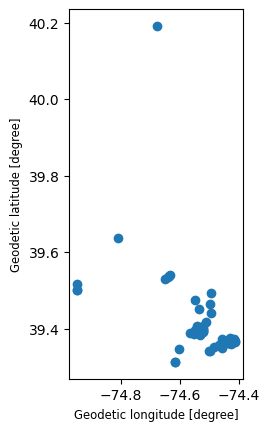

In [35]:
ATLgeo_full.plot()

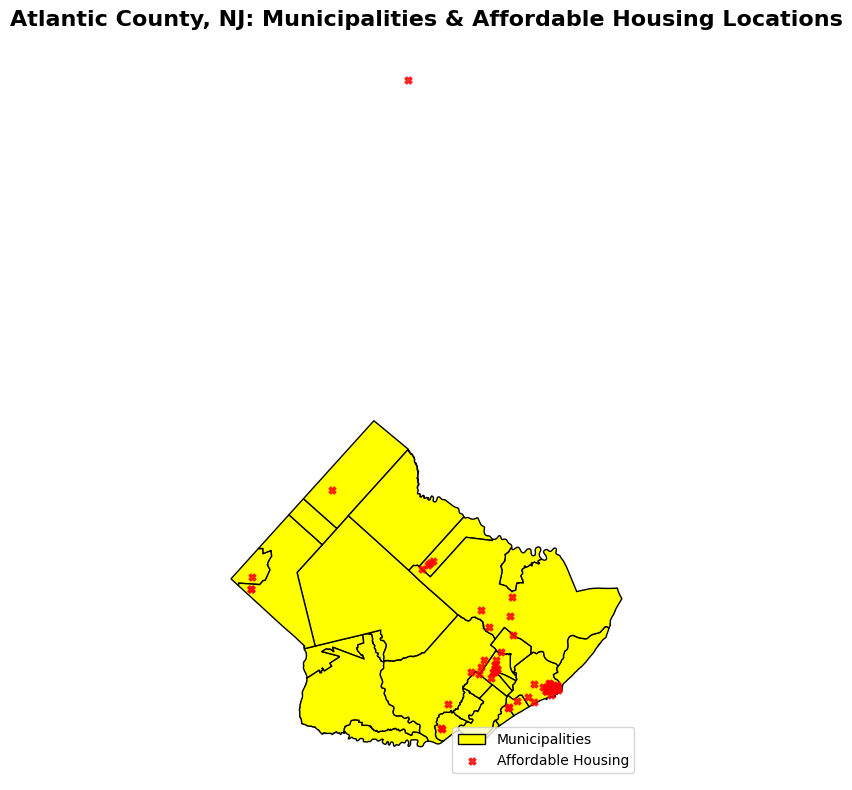

In [36]:
import matplotlib.pyplot as plt

# 1. Align Coordinate Reference Systems (CRS)
# Convert the geocoded points to match the municipal boundary CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Create the plot overlay
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the base map (Municipalities of Atlantic County)
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='YELLOW', linewidth=1, label='Municipalities')

# Plot the geocoded points of Affordable Housing
ATLgeo_projected.plot(ax=ax, marker='X', color='red', markersize=25, alpha=0.8, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

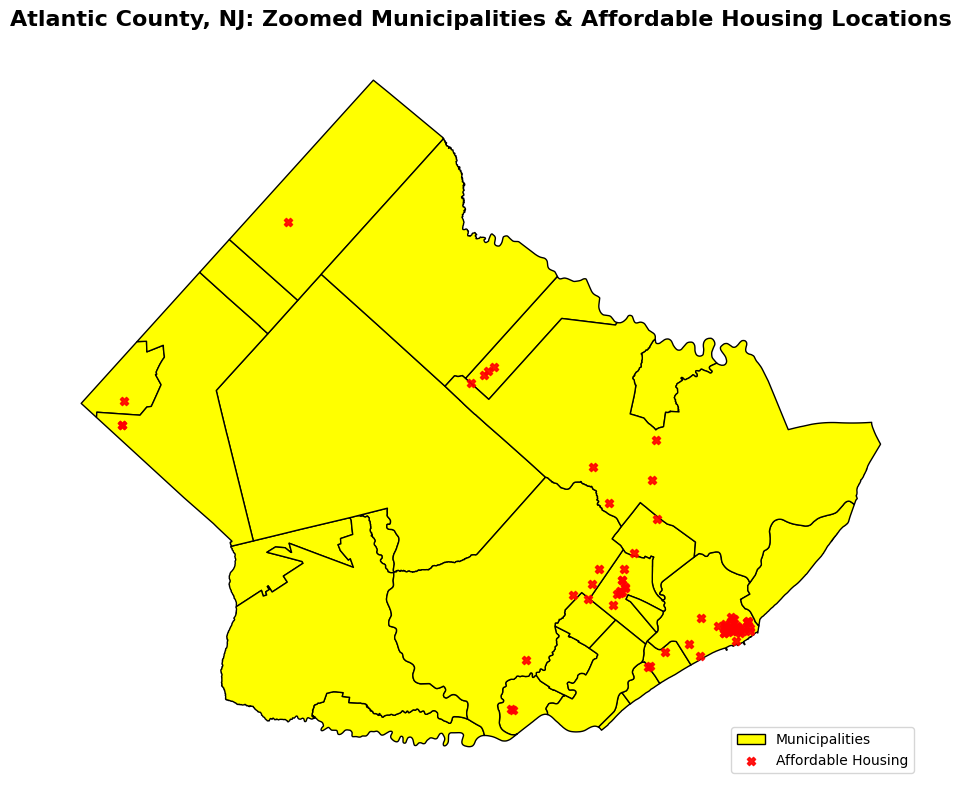

Removed 1 outlier point(s) located outside Atlantic County boundaries.


In [37]:
# 1. Align Coordinate Reference Systems (CRS) first
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Filter points spatially (keep only those inside the municipal boundaries)
# This removes any geocoding outliers that are outside Atlantic County
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')

# 3. Create the zoomed-in plot overlay
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the base map (Municipalities of Atlantic County)
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')

# Plot only the points that are within Atlantic County boundaries
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=35, alpha=0.9, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Zoomed Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Print status info
print(f"Removed {len(ATLgeo_projected) - len(ATLgeo_in_county)} outlier point(s) located outside Atlantic County boundaries.")

https://www.arcgis.com/home/item.html?id=95177982e99e46778881d34cb9ac4d99&sublayer=0

https://www.policymap.com/newmaps/e/rutgers

https://www.nj.gov/health/fhs/primarycare/rural-health/DesignatedRuralAreasinNewJersey.pdf

#Plotting Municipality Names

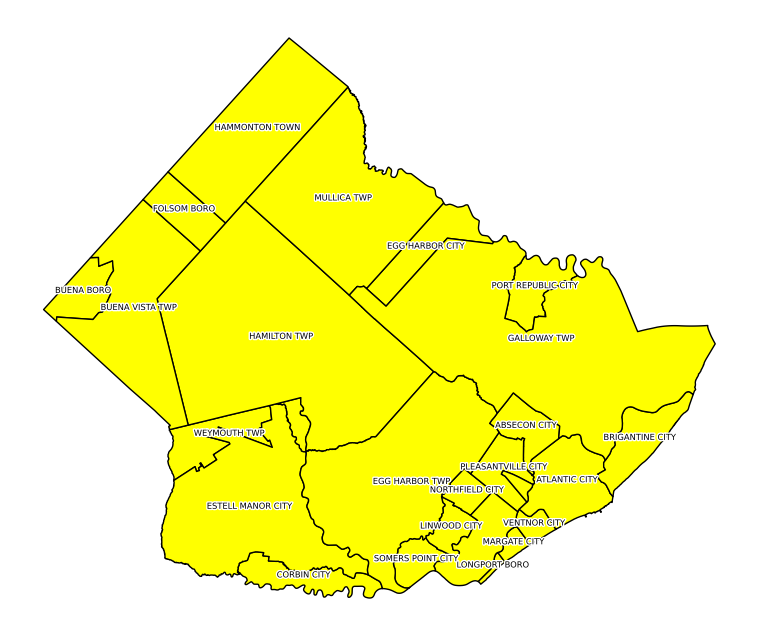

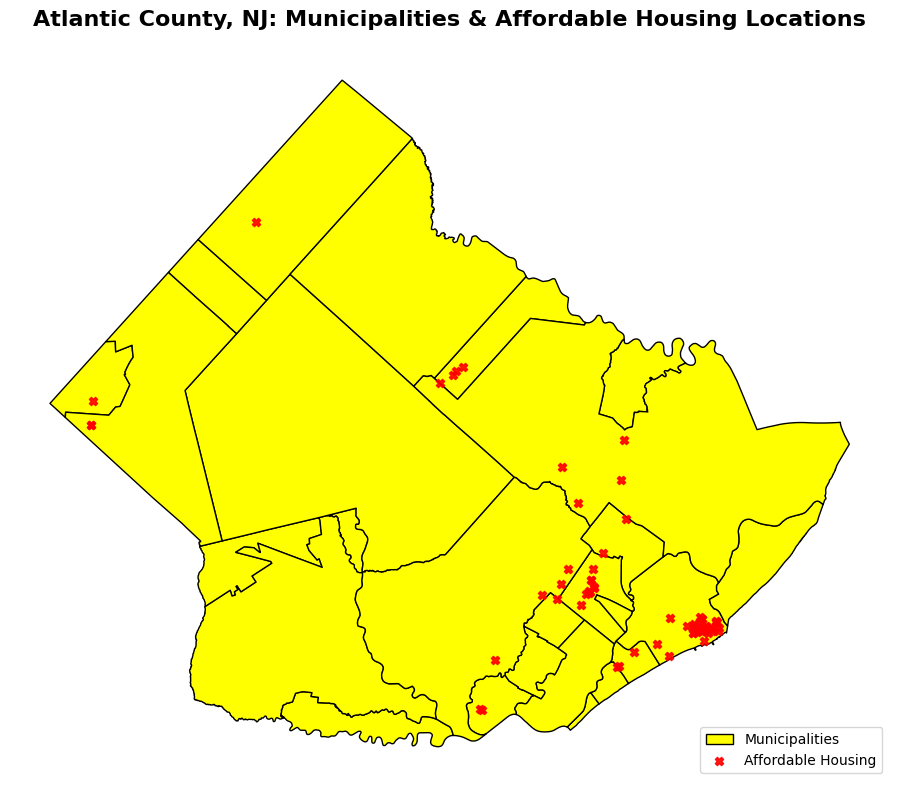

Removed 1 outlier point(s) located outside Atlantic County boundaries.


In [38]:
from matplotlib.patheffects import withStroke
import matplotlib.pyplot as plt

# Plot the base map
fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow')

# Extract the centroid coordinates of each municipality polygon for labeling
centroids = atlantic_mun_gdf.geometry.centroid

for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_gdf.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=6,
        color='black',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

plt.axis('off')
plt.show()

ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')
fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=35, alpha=0.9, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Print status info
print(f"Removed {len(ATLgeo_projected) - len(ATLgeo_in_county)} outlier point(s) located outside Atlantic County boundaries.")


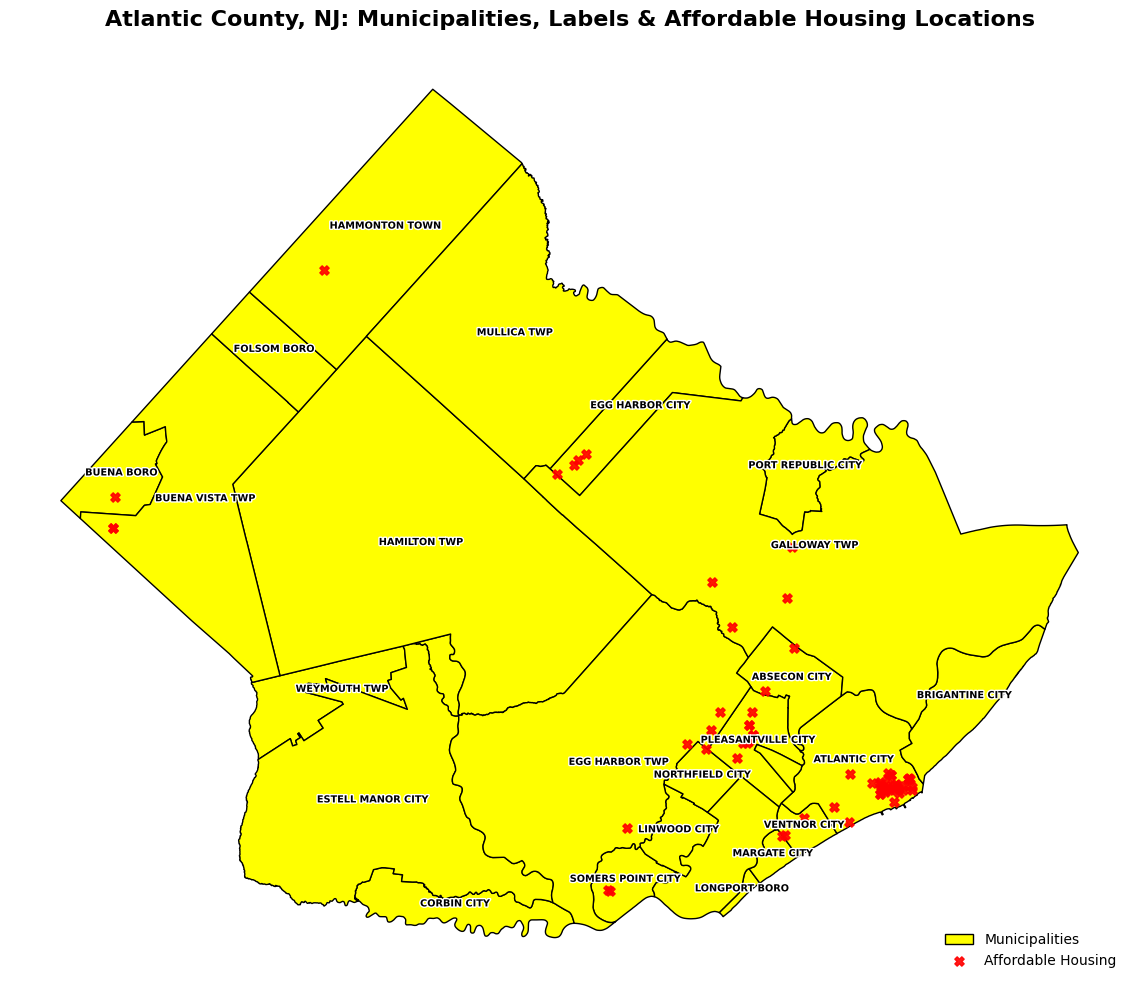

In [39]:
from matplotlib.patheffects import withStroke
import matplotlib.pyplot as plt
import geopandas as gpd

# 1. Project points to match the municipality CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Keep only housing points inside Atlantic County
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')

# 3. Create the combined plot
fig, ax = plt.subplots(figsize=(12, 10))

# Plot the yellow municipal boundaries
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')

# Plot the red affordable housing point markers
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=45, alpha=0.9, label='Affordable Housing')

# Add the municipal text labels at each polygon's centroid
centroids = atlantic_mun_gdf.geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_gdf.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=7,
        color='black',
        weight='bold',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

# Map styling
plt.title('Atlantic County, NJ: Municipalities, Labels & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

Including Population density into Atlantic County Municipalities for detailed Atlantic County Affordable Housing Developments.

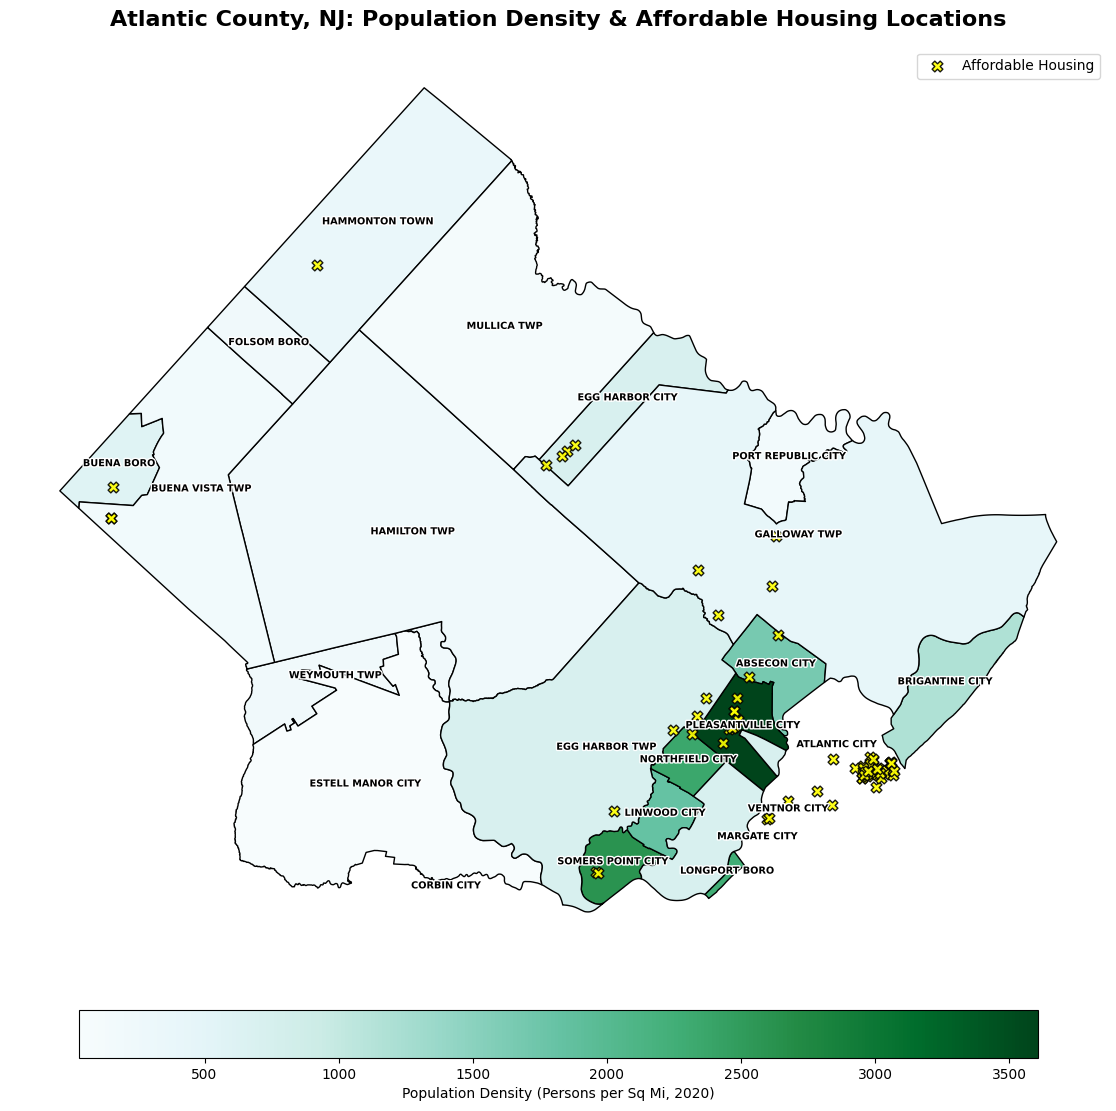

In [40]:
# 1. Clean municipality names to ensure a robust merge
atlantic_mun_gdf['clean_city'] = (atlantic_mun_gdf['MUN_LABEL']
                                  .str.replace(r'\s+(city|township|borough|town)$', '', regex=True, case=False)
                                  .str.strip()
                                  .str.lower())

# 2. Merge population density data into our spatial DataFrame
atlantic_mun_density = atlantic_mun_gdf.merge(pop_df, on='clean_city', how='left')

# 3. Project housing points to match the municipality CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_density.crs)

# 4. Filter housing points to stay strictly within Atlantic County using standard inner spatial join
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_density, how='inner', predicate='within')

# 5. Create the thematic map
fig, ax = plt.subplots(figsize=(14, 12))

# Plot the municipalities as a choropleth map of Population Density
atlantic_mun_density.plot(
    ax=ax,
    column='Persons per Sq Mi Census 2020',
    cmap='BuGn',
    edgecolor='black',
    linewidth=1,
    legend=True,
    legend_kwds={
        'label': 'Population Density (Persons per Sq Mi, 2020)',
        'orientation': 'horizontal',
        'shrink': 0.7,
        'pad': 0.05
    }
)

# Overlay the affordable housing points
ATLgeo_in_county.plot(
    ax=ax,
    marker='X',
    color='yellow',
    edgecolor='black',
    markersize=60,
    alpha=0.9,
    label='Affordable Housing'
)

# Add names/labels to the municipalities
from matplotlib.patheffects import withStroke
centroids = atlantic_mun_density.geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_density.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=7,
        color='black',
        weight='bold',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

# Map presentation tuning
plt.title('Atlantic County, NJ: Population Density & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.legend(loc='upper right', frameon=True, facecolor='white')
plt.axis('off')
plt.tight_layout()
plt.show()

#Final map interpretation
This map indicates that majority of Atlantic County affordable housing developments are closing to the Atlantic City area.  This is likely due to this being the area with the highest population density in the county.  Additional map could include median income or household size to compare if density is the only factor for affordable housing development presence.

#Cites

## References & Resources

### Data Sources
1. **New Jersey State & Municipal Boundaries (EPSG:3424)**
   * **Source:** New Jersey Office of GIS (NJOGIS)
   * **Portal:** [NJ Spatial Data Warehouse / NJ Open Data Portal](https://njogis-newjersey.opendata.arcgis.com/datasets/state-boundary-of-nj-3424/explore)
   * **Dataset Access:** Provided via the Anjanique-Knight GitHub Repository (`NJ_Municipal_Boundaries_3424.zip`)

2. **New Jersey Municipal Population & Density (Census 2020 / Estimates 2022)**
   * **Source:** New Jersey Department of Health / State Census Data
   * **Documentation:** [Designated Rural Areas in New Jersey (PDF)](https://www.nj.gov/health/fhs/primarycare/rural-health/DesignatedRuralAreasinNewJersey.pdf)
   * **Dataset Access:** Provided via the Anjanique-Knight GitHub Repository (`New_Jersey_Population_Density.xlsx`)

3. **Atlantic County Affordable Housing Developments**
   * **Source:** New Jersey Department of Community Affairs (NJ DCA)
   * **Portal:** [NJ DCA Codes & Standards Publications](https://www.nj.gov/dca/codes/publications/developments.shtml)
   * **Dataset Access:** Compiled and geocoded via the Anjanique-Knight GitHub Repository (`atlantic.xlsx`)

### Technology & APIs
1. **Geocoding API (Nominatim / OpenStreetMap)**
   * **Service:** OpenStreetMap Nominatim Geocoding engine
   * **Terms of Service:** [OSM Nominatim Usage Policy](https://operations.osmfoundation.org/policies/nominatim/) (Access mapped with a Python rate limiter restricting calls to 1 request per second).

2. **Spatial Analysis & Visualization Libraries**
   * **GeoPandas:** Spatial operations, CRS reprojections, and spatial joins.
   * **Pandas:** Data cleaning, merging, and matching evaluation using outer joins.
   * **Matplotlib & Seaborn:** Map visualizations, choropleths, labeling, and layout formatting.

Gemini Error Processing Cites
citations = {
    "Data & GIS Sources": [
        "New Jersey Counties & Municipal Boundaries Shapefiles: Hosted on GitHub (AjGIS repository by Anjanique-Knight).",
        "Atlantic County Affordable Housing Dataset (atlantic.xlsx): Hosted on GitHub (AjGIS repository).",
        "New Jersey Population Density Dataset (New_Jersey_Population_Density.xlsx): Hosted on GitHub (AjGIS repository)."
    ],
    "Geocoding Services": [
        "OpenStreetMap Nominatim API: Used via Geopy's RateLimiter to safely geocode addresses with an enforced delay policy."
    ],
    "Python Core Libraries": [
        "GeoPandas: Spatial operations, Coordinate Reference System (CRS) transformations, and map plotting.",
        "Pandas: Data manipulation, cleaning, and joining tables.",
        "Matplotlib: Spatial visualization, mapping layout styling, and custom styling with path effects (withStroke).",
        "Geopy / Nominatim: Client library to interface with OpenStreetMap's search API."
    ]
}

for category, entries in citations.items():
    print(f"=== {category} ===")
    for idx, entry in enumerate(entries, start=1):
        print(f"{idx}. {entry}")
    print()

## ps3

# Scatterplot of affordable housing developments across different income households

For this scatterplot I used all the affordable housing in Atlantic County against the median income for its municipalities.  

Intrepretation of this map show that the majority of affordable housing developments are located in places where the average Household income is between 25,000-50,000.00 annually.  With a large amount specifically between 20000-30000.

Based on the raw information and previous maps I can assume such areas are mainly in Atlantic City.

I believe Atlantic County is a good representation of placing affordable housing where it is needed.  In higher grossing areas like Linwood and even neighboring beach towns like Brigintine and Margate affordable housing developments are nowhere as prevalant with most being dedicated to seniors and the disabled rather than low income individuals and families.

In [41]:
!wget -q -O ACountyInc.xlsx https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/Atlantic_County_Census_Tracts_Consolidated.xlsx
import pandas as pd
ACountyInc = pd.read_excel('ACountyInc.xlsx')
ACountyInc.head(25)

,Atlantic County Census Tracts - Consolidated Demographic & Economic Data,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,Generated: Atlantic County Census Data | Conso...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Census Tract & Full ID,Municipality / Place,Tract Number,Full Tract GEOID,2020 Census Residents,2020-2024 ACS Residents,ACS Margin of Error,Median Household Income,Median Home Value,Median Rent,Poverty Rate
3,Tract 1 (34001000100),Atlantic City,Tract 1,34001000100,"2,334","2,380",±475,"$56,222","$212,100","$1,345",20.3%
4,Tract 2 (34001000200),Atlantic City,Tract 2,34001000200,"2,897","3,009",±549,"$42,346","$290,200","$1,375",20.7%
5,Tract 3 (34001000300),Atlantic City,Tract 3,34001000300,"4,027","4,064",±607,"$52,763","$162,500","$1,321",28.3%
6,Tract 4 (34001000400),Atlantic City,Tract 4,34001000400,"3,243","3,496",±493,"$50,104","$226,900","$1,219",30.4%
7,Tract 5 (34001000500),Atlantic City,Tract 5,34001000500,"3,012","2,944",±555,"$53,378","$163,800","$1,403",25.4%
8,Tract 11 (34001001100),Atlantic City,Tract 11,34001001100,"2,021","1,652",±260,"$38,869","$95,000",$602,22.8%
9,Tract 12 (34001001200),Atlantic City,Tract 12,34001001200,"2,834","2,769",±611,"$48,008","$131,800","$1,190",23.6%


In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# 1. Reconstruct merged_tract_data by combining census tract geometries with economic data
# Load the tract economics data
excel_path = 'ACountyInc.xlsx'
tract_econ_df = pd.read_excel(excel_path, sheet_name='Consolidated Census Data', skiprows=3)

tract_econ_df['Median_Income'] = pd.to_numeric(
    tract_econ_df['Median Household Income']
    .astype(str)
    .str.replace('$', '')
    .str.replace(',', ''),
    errors='coerce'
)

# Extract tract GEOID numeric code for matching
tract_econ_df['GEOID_clean'] = (
    tract_econ_df['Census Tract & Full ID']
    .astype(str)
    .str.extract(r'Tract \d+\s*\((\d+)\)')
)

# Standardize spatial tract IDs and merge housing development counts
tract_housing_counts = ac_tracts_final[['GEOID', 'housing_dev_count']].copy()
tract_housing_counts['GEOID'] = tract_housing_counts['GEOID'].astype(str)

merged_tract_data = tract_housing_counts.merge(
    tract_econ_df,
    left_on='GEOID',
    right_on='GEOID_clean',
    how='inner'
)

# 2. Prep data for regression analysis
income_col = 'Median_Income'
plot_df = merged_tract_data.dropna(subset=[income_col, 'housing_dev_count']).copy()

# Calculate Pearson Correlation (r) and R²
r_val, p_val = stats.pearsonr(plot_df[income_col], plot_df['housing_dev_count'])
r_squared = r_val**2

# 3. Plot Scatter Plot with OLS Regression Line
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=plot_df,
    x=income_col,
    y='housing_dev_count',
    ax=ax,
    color='#1f77b4',
    scatter_kws={'s': 70, 'alpha': 0.8, 'edgecolor': 'black'},
    line_kws={
        'color': '#d62728',
        'linewidth': 2,
        'label': f'OLS Trendline\n(r = {r_val:.2f}, R² = {r_squared:.2f}, p = {p_val:.3f})'
    }
)

plt.title(
    'Atlantic County Census Tracts: Median Income vs. Affordable Housing Counts',
    fontsize=13,
    fontweight='bold',
    pad=15
)
plt.xlabel('Census Tract Median Household Income ($)', fontsize=11, fontweight='bold')
plt.ylabel('Number of Affordable Housing Developments', fontsize=11, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

NameError: name 'ac_tracts_final' is not defined

# Simplifying Atlantic City and local municipalities

In [ ]:
ac_mun = atlantic_mun_gdf[atlantic_mun_gdf['clean_city'] == 'atlantic city'].copy()

In [ ]:
ac_housing = ATLgeo_full[ATLgeo_full['clean_city'] == 'atlantic city'].copy()

In [ ]:
# Direct URL to Census TIGER 2020 Tract zipfile for NJ
url = "https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_34_tract.zip"
nj_tracts = gpd.read_file(url)
atl_tracts = nj_tracts[nj_tracts["COUNTYFP"] == "001"].to_crs("EPSG:3424")

In [ ]:
from matplotlib.patheffects import withStroke
import matplotlib.pyplot as plt
import geopandas as gpd

# 1. Create a 15,000 feet buffer around Atlantic City to find adjacent municipalities
ac_buffer = ac_boundary_3424.geometry.buffer(15000)
surrounding_mun = atlantic_mun_gdf[atlantic_mun_gdf.to_crs("EPSG:3424").intersects(ac_buffer.union_all())].copy()

# 2. Setup the visualization plot
fig, ax = plt.subplots(figsize=(12, 12))

# Plot surrounding municipal boundaries in a neutral light gray
surrounding_mun.to_crs("EPSG:3424").plot(ax=ax, color="#f0f0f0", edgecolor="#cbcbcb", linewidth=1)

# Fill Atlantic City area with a light background
ac_boundary_3424.plot(ax=ax, color="#dbeafe", edgecolor="none", alpha=0.5)

# Overlay census tracts inside Atlantic City
ac_tracts_fixed.plot(ax=ax, color="#3b82f6", edgecolor="black", alpha=0.75, linewidth=0.5, label="Census Tracts")

# Overlay a distinct red boundary line around Atlantic City
ac_boundary_3424.plot(ax=ax, facecolor="none", edgecolor="#dc2626", linewidth=3, label="Atlantic City Boundary")

# 3. Label surrounding municipalities by their polygon centroids
centroids = surrounding_mun.to_crs("EPSG:3424").geometry.centroid
for x_coord, y_coord, label in zip(centroids.x, centroids.y, surrounding_mun.MUN_LABEL):
    # Strip suffixes to keep labels concise
    clean_label = label.replace(" Borough", "").replace(" City", "").replace(" Township", "")
    ax.annotate(
        clean_label,
        xy=(x_coord, y_coord),
        horizontalalignment='center',
        fontsize=8,
        color='#475569',
        weight='bold',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

# Final plot layout tuning
plt.title("Atlantic City Census Tracts & Surrounding Municipalities", fontsize=16, fontweight="bold", pad=15)
plt.axis("off")
plt.xlim(ac_boundary_3424.total_bounds[0] - 20000, ac_boundary_3424.total_bounds[2] + 20000)
plt.ylim(ac_boundary_3424.total_bounds[1] - 15000, ac_boundary_3424.total_bounds[3] + 15000)
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.show()

# Introducting Atlantic City population, income, and poverty stats

In [ ]:
csvACPop=pd.read_csv('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/ACSST5Y2024.S0101-2026-10-19T125239.csv')
csvACPop.head()

In [ ]:
csvACPov=pd.read_csv('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/ACSST5Y2024.S1701-2026-10-19T130823.csv')
csvACPov.head()

In [ ]:
csvACinc=pd.read_csv('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/ACSST5Y2024.S1901-2026-10-19T125354.csv')
csvACinc.head()

# Merge AC demographic inforamtion

In [ ]:
# 1. Create the ac_demographics DataFrame by extracting relevant metrics from our loaded Census sheets
# We'll pull the row labels and their corresponding estimate columns
total_pop_val = csvACPop.loc[csvACPop['Label (Grouping)'].str.contains('Total population', na=False), 'Atlantic City city, New Jersey!!Total!!Estimate'].values[0]
poverty_pop_val = csvACPov.loc[csvACPov['Label (Grouping)'].str.contains('Population for whom poverty status is determined', na=False), 'Atlantic City city, Atlantic County, New Jersey!!Below poverty level!!Estimate'].values[0]

# Clean string formatting (remove commas)
total_pop = float(str(total_pop_val).replace(',', ''))
poverty_pop = float(str(poverty_pop_val).replace(',', ''))

# 2. Build the combined demographics DataFrame
ac_demographics = pd.DataFrame({
    "city": ["Atlantic City"],
    "total_population": [total_pop],
    "below_poverty_level": [poverty_pop]
})

# 3. Calculate Poverty Rate percentage cleanly
ac_demographics["poverty_rate"] = (ac_demographics["below_poverty_level"] / ac_demographics["total_population"]) * 100

# Display the structured DataFrame
display(ac_demographics)

In [ ]:
# 1. Map our city-wide demographic details safely onto the 23 isolated Atlantic City tracts (ac_tracts_fixed)
ac_tracts_demog = ac_tracts_fixed.copy()

# Extract calculated values from the ac_demographics DataFrame
city_poverty_rate = ac_demographics.loc[0, "poverty_rate"]
city_total_pop = ac_demographics.loc[0, "total_population"]

# Assign the city-wide demographic attributes to the tracts
ac_tracts_demog["city_total_pop"] = city_total_pop
ac_tracts_demog["city_poverty_rate"] = city_poverty_rate

# 2. Display the joined attributes with properly closed brackets and parentheses
display(ac_tracts_demog[["GEOID", "NAMELSAD", "city_total_pop", "city_poverty_rate"]].head())

In [ ]:
# 1. Filter PS2 housing points for Atlantic City and project CRS
ac_housing = ATLgeo_full[ATLgeo_full["clean_city"] == "atlantic city"].copy()
ac_housing_proj = ac_housing.to_crs("EPSG:3424")

# 2. Spatial join: attach tract GEOID to each geocoded housing point
housing_in_tracts = gpd.sjoin(
    ac_housing_proj, ac_tracts_demog[["GEOID", "geometry"]], predicate="within"
)

# 3. Aggregate total affordable housing developments per tract
tract_counts = (
    housing_in_tracts.groupby("GEOID")
    .size()
    .reset_index(name="housing_dev_count")
)

# 4. Merge development counts back into the main tract spatial dataset
ac_tracts_final = ac_tracts_demog.merge(tract_counts, on="GEOID", how="left")
ac_tracts_final["housing_dev_count"] = ac_tracts_final[
    "housing_dev_count"
].fillna(0)

# Raster Map of affordable housing development site density

Intrepretation of this maps shows majority of affordable housing development sites are in the south eastern part of the city.  

This cluster map also shows little to no continuous density in other areas of the city and closer to the more expensive shores towns like Brigintine or Ventnor that have significantly higher median home sales price.

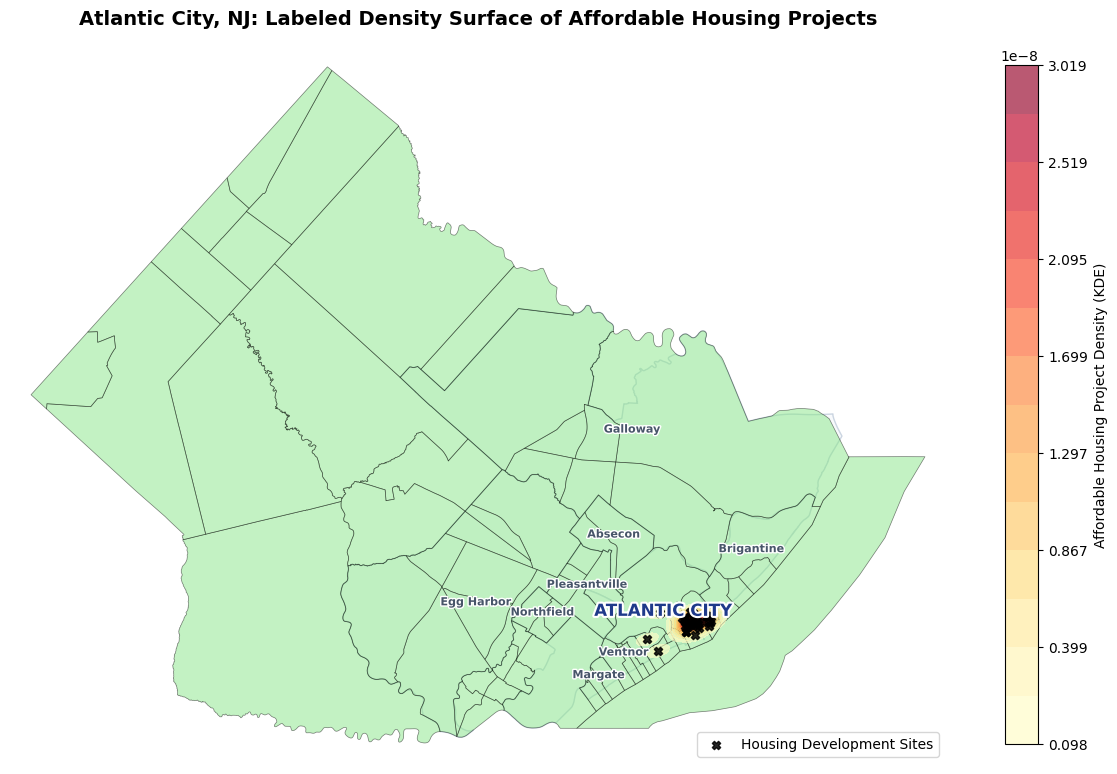

In [23]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patheffects import withStroke

# 1. Project datasets to local CRS
ac_housing = ATLgeo_full[ATLgeo_full['clean_city'] == 'atlantic city'].copy()
ac_housing_proj = ac_housing.to_crs('EPSG:3424')
ac_tracts_proj = ac_tracts_fixed.to_crs('EPSG:3424')
ac_boundary_proj = ac_boundary_3424.to_crs('EPSG:3424')

# Get surrounding municipalities to draw boundaries and labels
ac_buffer = ac_boundary_proj.geometry.buffer(10000)
surrounding_mun = atlantic_mun_gdf[atlantic_mun_gdf.to_crs('EPSG:3424').intersects(ac_buffer.union_all())].copy()

x_coords = ac_housing_proj.geometry.x
y_coords = ac_housing_proj.geometry.y

# 2. Build the Density Surface Plot
fig, ax = plt.subplots(figsize=(12, 10))

# Plot surrounding municipal boundaries
surrounding_mun.to_crs('EPSG:3424').plot(ax=ax, color='#f8fafc', edgecolor='#cbd5e1', linewidth=1)

# Base Layer: Atlantic City Census Tract Boundaries
ac_tracts_proj.plot(ax=ax, facecolor='#88E788', edgecolor='black', linewidth=0.5, alpha=0.5)

# Continuous Raster Layer: 2D KDE Heatmap
sns.kdeplot(
    x=x_coords,
    y=y_coords,
    ax=ax,
    fill=True,
    cmap='YlOrRd',
    alpha=0.65,
    thresh=0.05,
    levels=15,
    cbar=True,
    cbar_kws={
        'label': 'Affordable Housing Project Density (KDE)',
        'shrink': 0.7,
    }
)

# Point Overlay: Individual Geocoded Housing Project Sites
ac_housing_proj.plot(
    ax=ax,
    marker='X',
    color='black',
    markersize=35,
    alpha=0.85,
    label='Housing Development Sites'
)

# 3. Label Municipalities & Atlantic City
centroids = surrounding_mun.to_crs('EPSG:3424').geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, surrounding_mun.MUN_LABEL):
    clean_label = label.replace(' Borough', '').replace(' City', '').replace(' Township', '')
    if clean_label.lower() != 'atlantic':
        ax.annotate(
            clean_label,
            xy=(x, y),
            horizontalalignment='center',
            fontsize=8,
            color='#475569',
            weight='bold',
            path_effects=[withStroke(linewidth=2, foreground='white')]
        )

# Add prominent label for Atlantic City itself
ac_centroid = ac_boundary_proj.geometry.centroid.iloc[0]
ax.annotate(
    'ATLANTIC CITY',
    xy=(ac_centroid.x, ac_centroid.y - 3000),
    horizontalalignment='center',
    fontsize=12,
    color='#1e3a8a',
    weight='black',
    path_effects=[withStroke(linewidth=3, foreground='white')]
)

# 4. Zoom Extent & Formatting
minx, miny, maxx, maxy = ac_tracts_proj.total_bounds
ax.set_xlim(minx - 5000, maxx + 5000)
ax.set_ylim(miny - 5000, maxy + 5000)

plt.title('Atlantic City, NJ: Labeled Density Surface of Affordable Housing Projects', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='lower right', frameon=True, facecolor='white')
plt.axis('off')
plt.tight_layout()
plt.show()

#add additional attributes like size of property, vacancy, units availble or rent priced

# %poverty

# AC Neighborhood Cluster Map

After adding more detail in the particular census tracts throughout the city we see the continuous densisty is specifically high in neighborhoods like Downtown, Midtown, and the Inlet.  

As a Property Manager in the area i will note that both the Atlantic City Housing Authoirty OFfice and Field office for DCA Housing Choice Vouchers are in these neighborhoods.

Specifically right in the center of the cluster is Altman Plaza a large affordable housing high rise in the backyard of the ACHA Mangement Office.

Given the size of Atlantic City clustering is expected however, so many developments overlapping raises questions of specific zoning for the purpose of management by field offices or to maitain a specific environment for other higher income areas of Atlantic City like Chelsea heights for instance.  


In [37]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

# 1. Define your neighborhoods with Latitude and Longitude coordinates (from Google Maps)
# You can add or edit coordinates in this dictionary as you find new ones!
neighborhood_gps = {
    'Inlet Neighborhood': {'lat': 39.3796, 'lon': -74.4213},
    'Downtown Area': {'lat': 39.3606, 'lon': -74.4319},
    'Midtown Neighborhood': {'lat': 39.36012, 'lon': -74.43301},
    'Ducktown Neighborhood': {'lat': 39.3566, 'lon': -74.4419},
    'Chelsea Neighborhood': {'lat': 39.3559, 'lon': -74.4627},
    'Lower Chelsea': {'lat': 39.3540, 'lon': -74.4491},
    'Venice Park': {'lat': 39.3765, 'lon': -74.4451},
    'Bungalow Park': {'lat': 39.3732, 'lon': -74.4230}}

# 2. Convert dictionary to DataFrame and then to a GeoDataFrame in standard GPS CRS (EPSG:4326)
df_gps = pd.DataFrame.from_dict(neighborhood_gps, orient='index').reset_index()
df_gps.columns = ['Neighborhood', 'Latitude', 'Longitude']

geometry = [Point(xy) for xy in zip(df_gps['Longitude'], df_gps['Latitude'])]
gdf_gps = gpd.GeoDataFrame(df_gps, geometry=geometry, crs="EPSG:4326")

# 3. Transform to Projected CRS (EPSG:3424)
gdf_projected = gdf_gps.to_crs("EPSG:3424")

# 4. Extract and print formatted projected coordinate pairs
print("=== CONVERTED EPSG:3424 STATE PLANE COORDINATES (FEET) ===\n")
for idx, row in gdf_projected.iterrows():
    easting = row.geometry.x
    northing = row.geometry.y
    print(f"Neighborhood: {row['Neighborhood']}")
    print(f"  GPS Lat/Lon: {row['Latitude']:.6f}, {row['Longitude']:.6f}")
    print(f"  Projected (Easting, Northing): ({easting:.2f}, {northing:.2f})")
    print("-" * 50)

=== CONVERTED EPSG:3424 STATE PLANE COORDINATES (FEET) ===

Neighborhood: Inlet Neighborhood
  GPS Lat/Lon: 39.379600, -74.421300
  Projected (Easting, Northing): (514369.85, 198956.48)
--------------------------------------------------
Neighborhood: Downtown Area
  GPS Lat/Lon: 39.360600, -74.431900
  Projected (Easting, Northing): (511378.93, 192034.06)
--------------------------------------------------
Neighborhood: Midtown Neighborhood
  GPS Lat/Lon: 39.360120, -74.433010
  Projected (Easting, Northing): (511065.23, 191859.00)
--------------------------------------------------
Neighborhood: Ducktown Neighborhood
  GPS Lat/Lon: 39.356600, -74.441900
  Projected (Easting, Northing): (508552.57, 190575.25)
--------------------------------------------------
Neighborhood: Chelsea Neighborhood
  GPS Lat/Lon: 39.355900, -74.462700
  Projected (Easting, Northing): (502671.55, 190317.19)
--------------------------------------------------
Neighborhood: Lower Chelsea
  GPS Lat/Lon: 39.354000,

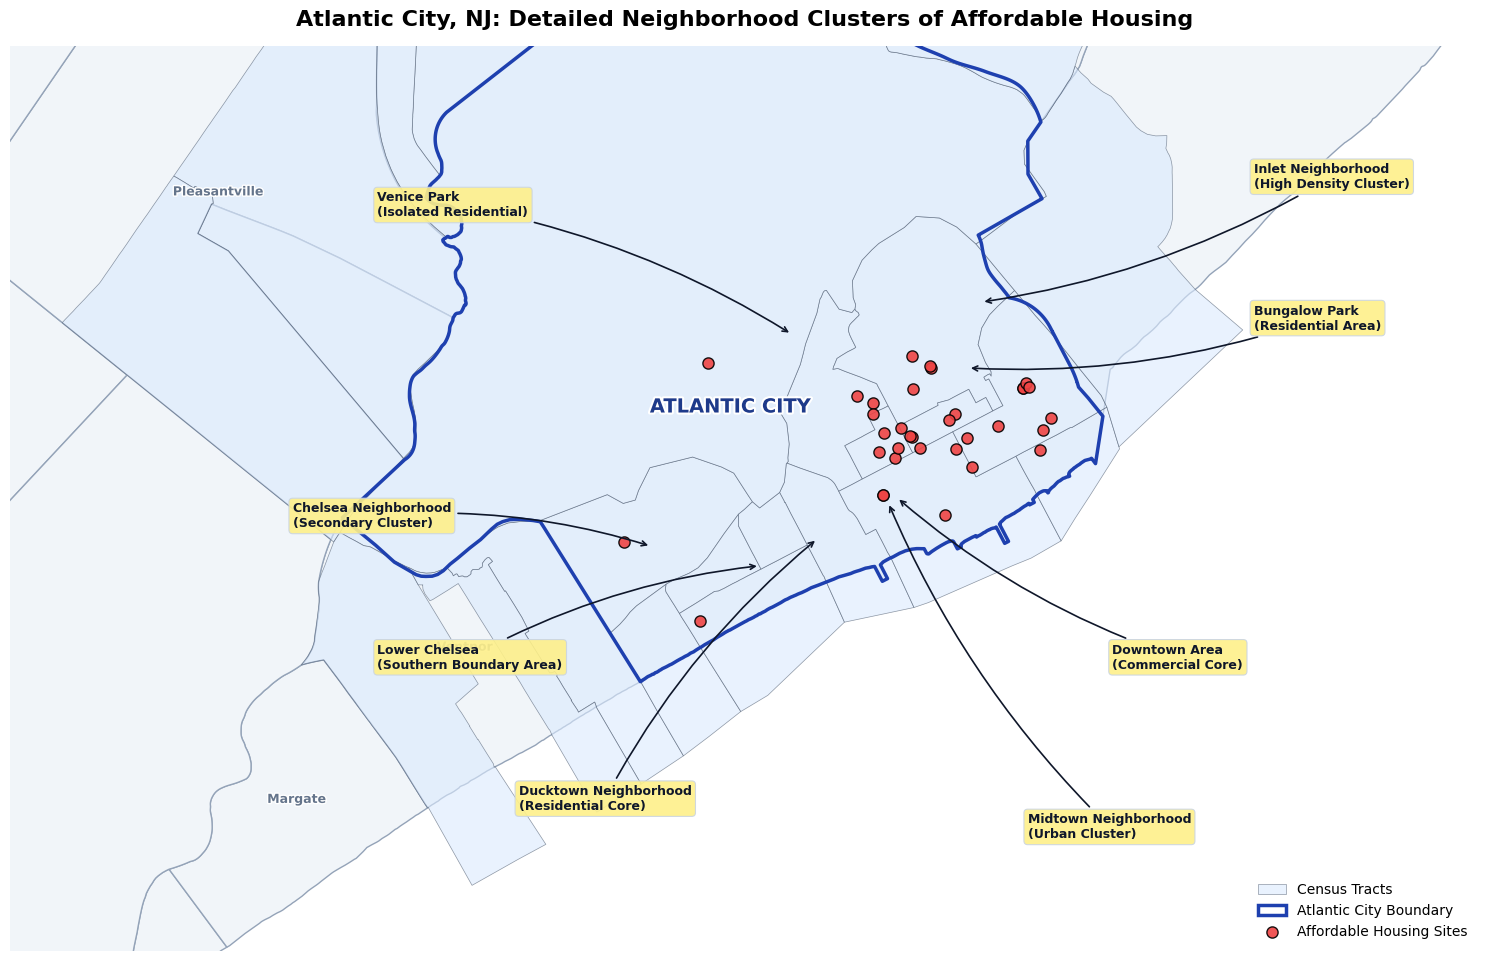

In [38]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patheffects import withStroke
import pandas as pd
from shapely.geometry import Point
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# 0. Re-create municipal and tract dependencies
try:
    gdf_mun = gpd.read_file('NJ_Municipal_Boundaries_3424.shp')
except Exception:
    import zipfile
    !wget -q -O njMun.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Municipal_Boundaries_3424_-6792731789006169525.zip
    with zipfile.ZipFile('njMun.zip', 'r') as zip_ref:
        zip_ref.extractall()
    gdf_mun = gpd.read_file('NJ_Municipal_Boundaries_3424.shp')

atlantic_mun_gdf = gdf_mun[gdf_mun['COUNTY'] == 'ATLANTIC'].copy()
atlantic_mun_gdf['clean_city'] = atlantic_mun_gdf['MUN_LABEL'].str.replace(r'\s+(city|township|borough|town)$', '', regex=True, case=False).str.strip().str.lower()

url_tracts = "https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_34_tract.zip"
nj_tracts = gpd.read_file(url_tracts)
atl_tracts = nj_tracts[nj_tracts["COUNTYFP"] == "001"].to_crs("EPSG:3424")

global ATLgeo_full
try:
    ATLgeo_full
except NameError:
    print("ATLgeo_full not found in memory. Loading and geocoding housing data...")
    ATLhome_full = pd.read_excel("https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/atlantic.xlsx")
    valid_homes_full = ATLhome_full[~ATLhome_full['street'].astype(str).str.contains('intentional blank', case=False, na=True)].copy()
    valid_homes_full['full_address'] = valid_homes_full['street'].astype(str) + ', ' + valid_homes_full['City '].astype(str) + ', NJ'
    geolocator = Nominatim(user_agent="nj_affordable_housing_mapper_aj_9d_v2")
    geocode_with_delay = RateLimiter(geolocator.geocode, min_delay_seconds=1.1, return_value_on_exception=None)
    valid_homes_full['location'] = valid_homes_full['full_address'].apply(geocode_with_delay)
    valid_homes_full['point'] = valid_homes_full['location'].apply(lambda loc: Point(loc.longitude, loc.latitude) if loc else None)
    final_geocoded = valid_homes_full.dropna(subset=['point']).copy()
    ATLgeo_full = gpd.GeoDataFrame(final_geocoded, geometry='point', crs="EPSG:4326")
    ATLgeo_full['clean_city'] = ATLgeo_full['City '].astype(str).str.strip().str.lower()

# Extract AC boundary and tracts
ac_boundary_3424 = atlantic_mun_gdf[atlantic_mun_gdf['clean_city'] == 'atlantic'].to_crs("EPSG:3424")
ac_tracts_fixed = atl_tracts[atl_tracts['GEOID'].isin(atl_tracts['GEOID'])].to_crs("EPSG:3424")

ac_boundary_proj = ac_boundary_3424.copy()
ac_housing_proj = ATLgeo_full[ATLgeo_full['clean_city'] == 'atlantic city'].to_crs('EPSG:3424')
ac_tracts_proj = ac_tracts_fixed.to_crs('EPSG:3424')

# Filter to keep only tracts belonging to Atlantic City bounds to prevent map-drift
ac_tracts_ac_only = gpd.sjoin(ac_tracts_proj, ac_boundary_proj, how='inner', predicate='intersects')

ac_buffer = ac_boundary_proj.geometry.buffer(15000)
surrounding_mun = atlantic_mun_gdf[atlantic_mun_gdf.to_crs('EPSG:3424').intersects(ac_buffer.union_all())].copy()

fig, ax = plt.subplots(figsize=(15, 13))
surrounding_mun.to_crs('EPSG:3424').plot(ax=ax, color='#f1f5f9', edgecolor='#94a3b8', linewidth=1)
ac_tracts_ac_only.plot(ax=ax, color='#dbeafe', edgecolor='#475569', alpha=0.6, linewidth=0.5, label='Census Tracts')
ac_boundary_proj.plot(ax=ax, facecolor='none', edgecolor='#1e40af', linewidth=2.5, label='Atlantic City Boundary')

# Plot the geocoded affordable housing project markers with higher visibility
ac_housing_proj.plot(ax=ax, marker='o', color='#ef4444', markersize=65, edgecolor='black', linewidth=1.0, alpha=0.9, label='Affordable Housing Sites')

# Label surrounding municipalities
centroids = surrounding_mun.to_crs('EPSG:3424').geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, surrounding_mun.MUN_LABEL):
    clean_label = label.replace(' Borough', '').replace(' City', '').replace(' Township', '')
    if clean_label.lower() != 'atlantic':
        ax.annotate(
            clean_label,
            xy=(x, y),
            horizontalalignment='center',
            fontsize=9,
            color='#64748b',
            weight='bold',
            path_effects=[withStroke(linewidth=2, foreground='white')]
        )

# Add prominent label for Atlantic City
ac_centroid = ac_boundary_proj.geometry.centroid.iloc[0]
ax.annotate(
    'ATLANTIC CITY',
    xy=(ac_centroid.x, ac_centroid.y - 4000),
    horizontalalignment='center',
    fontsize=14,
    color='#1e3a8a',
    weight='black',
    path_effects=[withStroke(linewidth=3, foreground='white')]
)

# Geographically corrected coordinates based on EPSG:3424 conversions
neighborhood_annotations = [
    {
        'name': 'Inlet Neighborhood\n(High Density Cluster)',
        'coord': (514369.85, 198956.48),
        'text_coord': (524000, 203000),
    },
    {
        'name': 'Bungalow Park\n(Residential Area)',
        'coord': (513891.32, 196625.12),
        'text_coord': (524000, 198000),
    },
    {
        'name': 'Downtown Area\n(Commercial Core)',
        'coord': (511378.93, 192034.06),
        'text_coord': (519000, 186000),
    },
    {
        'name': 'Midtown Neighborhood\n(Urban Cluster)',
        'coord': (511065.23, 191859.00),
        'text_coord': (516000, 180000),
    },
    {
        'name': 'Ducktown Neighborhood\n(Residential Core)',
        'coord': (508552.57, 190575.25),
        'text_coord': (498000, 181000),
    },
    {
        'name': 'Lower Chelsea\n(Southern Boundary Area)',
        'coord': (506517.33, 189627.07),
        'text_coord': (493000, 186000),
    },
    {
        'name': 'Chelsea Neighborhood\n(Secondary Cluster)',
        'coord': (502671.55, 190317.19),
        'text_coord': (490000, 191000),
    },
    {
        'name': 'Venice Park\n(Isolated Residential)',
        'coord': (507643.37, 197822.46),
        'text_coord': (493000, 202000),
    },
]

for note in neighborhood_annotations:
    ax.annotate(
        note['name'],
        xy=note['coord'],
        xytext=note['text_coord'],
        arrowprops=dict(
            arrowstyle='->',
            color='#0f172a',
            lw=1.2,
            connectionstyle='arc3,rad=-0.1',
        ),
        fontsize=9,
        weight='bold',
        color='#0f172a',
        bbox=dict(
            boxstyle='round,pad=0.3',
            facecolor='#fef08a',
            edgecolor='#cbd5e1',
            alpha=0.9,
            lw=0.8,
        ),
    )

plt.title(
    'Atlantic City, NJ: Detailed Neighborhood Clusters of Affordable Housing',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
ax.set_xlim(480000, 532000)
ax.set_ylim(176000, 208000)
plt.axis('off')
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

In [20]:
import geopandas as gpd
from shapely.geometry import Point

# Create a point using Longitude (X), Latitude (Y) in EPSG:4326 (WGS84)
ducktown_lon_lat = Point(-74.44177152894959, 39.35785225181131)

# Wrap it in a GeoSeries with the correct CRS
gdf_temp = gpd.GeoSeries([ducktown_lon_lat], crs="EPSG:4326")

# Transform to local state plane system (EPSG:3424)
gdf_projected = gdf_temp.to_crs("EPSG:3424")

projected_point = gdf_projected.iloc[0]
print(f"Projected Coordinates (X, Y) in EPSG:3424:")
print(f"Easting (X): {projected_point.x:.2f}")
print(f"Northing (Y): {projected_point.y:.2f}")

Projected Coordinates (X, Y) in EPSG:3424:
Easting (X): 508588.60
Northing (Y): 191031.35


In [25]:
# Corrected Diagnosing Geocoded Locations and Projections
import geopandas as gpd

print("=== CRS Check ===")
print(f"Municipal boundaries CRS: {atlantic_mun_gdf.crs}")
print(f"Raw geocoded housing CRS: {ATLgeo_full.crs}")
print(f"Active geometry column: {ATLgeo_full.geometry.name}")
print(f"DataFrame Columns: {list(ATLgeo_full.columns)}")

# Sample 5 geocoded points using the correct active geometry column ('point')
print("\n=== Sample Geocoded Results (WGS84) ===")
geom_col = ATLgeo_full.geometry.name
display(ATLgeo_full[['street', 'City ', geom_col]].head(5))

# Perform a test projection to local coordinates (EPSG:3424)
test_projected = ATLgeo_full.to_crs("EPSG:3424")
print("\n=== Projected Coordinate Bounds (Local Feet) ===")
print(test_projected.total_bounds)
print("Municipal Map Bounds (Local Feet):")
print(atlantic_mun_gdf.total_bounds)


=== CRS Check ===
Municipal boundaries CRS: EPSG:3424
Raw geocoded housing CRS: EPSG:4326
Active geometry column: point
DataFrame Columns: ['o', 'seq', 'ltd', 'source', 'notes', 'proj_no', 'pro_no_2', 'Unnamed: 7', 'development / aka', 'aka', 'street', 'street_2', 'Unnamed: 12', 'municipality', 'muni_2', 'county', 'comu', 'comu_2', 'st', 'zip', 'Unnamed: 20', 'City ', 'type', 'tenure', 'units', 'Unnamed: 25', 'property', 'ph_srce', 'area', 'phone', 'agent', 'agent address', 'area_2', 'phone_2', 'website', 'Unnamed: 35', 'program', 'date', 'seq.1', 'full_address', 'location', 'point', 'clean_city']

=== Sample Geocoded Results (WGS84) ===


,street,City,point
3,600 Rose Hill Dr,Absecon,POINT (-74.51256 39.41702)
4,3 School View Dr,Absecon,POINT (-74.49304 39.43958)
5,227 N Vermont Av,Atlantic City,POINT (-74.41612 39.37123)
6,334 N Tennesee Av,Atlantic City,POINT (-74.42594 39.35893)
7,46 N Connecticut Av,Atlantic City,POINT (-74.41922 39.36751)



=== Projected Coordinate Bounds (Local Feet) ===
[365188.81098014 174672.85680457 516815.70508624 494591.5265164 ]
Municipal Map Bounds (Local Feet):
[355226.27364691 165824.2351784  548022.84179316 326575.60133907]


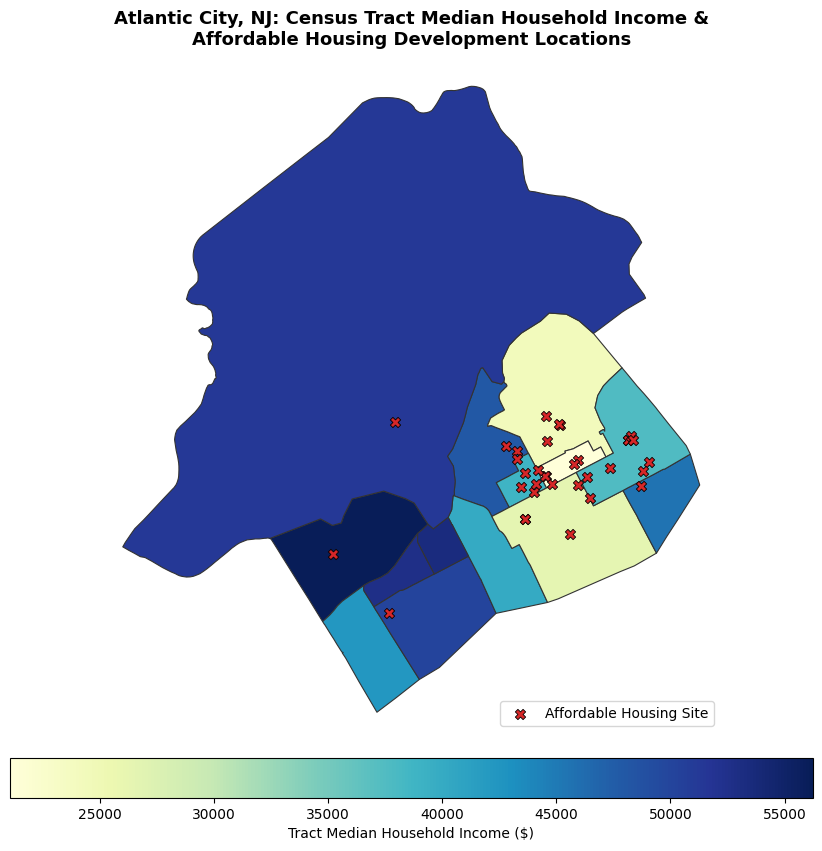

In [26]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Prepare Spatial Tract Boundaries & Income Data Properly
# ---------------------------------------------------------
# Download ACountyInc.xlsx if it does not already exist
!wget -q -O ACountyInc.xlsx https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/Atlantic_County_Census_Tracts_Consolidated.xlsx

# Reload ACountyInc skipping the top 3 descriptive metadata rows to align column headers correctly
ACountyInc_fixed = pd.read_excel('ACountyInc.xlsx', sheet_name='Consolidated Census Data', skiprows=3)

# Clean and format 'Median Household Income' to numeric values
ACountyInc_fixed['Median_Income'] = pd.to_numeric(
    ACountyInc_fixed['Median Household Income']
    .astype(str)
    .str.replace('$', '')
    .str.replace(',', ''),
    errors='coerce'
)

# Extract and clean GEOID
ACountyInc_fixed['GEOID'] = (
    ACountyInc_fixed['Census Tract & Full ID']
    .astype(str)
    .str.extract(r'Tract \d+\s*\((\d+)\)')
)
if 'GEOID' in ACountyInc_fixed.columns:
    ACountyInc_fixed['GEOID'] = ACountyInc_fixed['GEOID'].astype(str).str.zfill(11)

income_col = 'Median_Income'
city_col = 'Municipality / Place'

# Filter census tract data for Atlantic City
ac_tracts_data = ACountyInc_fixed[
    ACountyInc_fixed[city_col].astype(str).str.lower().str.contains('atlantic city')
].copy()

# Filter spatial tract polygons for Atlantic City and reproject to EPSG:3424
ac_tracts_geo = atl_tracts[
    atl_tracts['GEOID'].isin(ac_tracts_data['GEOID'])
].to_crs('EPSG:3424')

# Merge median household income into spatial tract polygons
city_income_map = ac_tracts_geo.merge(
    ac_tracts_data[['GEOID', income_col]], on='GEOID', how='left'
)

# Filter and reproject Atlantic City geocoded housing points
ac_housing_pts = ATLgeo_full[
    ATLgeo_full['clean_city'].astype(str).str.lower() == 'atlantic city'
].to_crs('EPSG:3424')

# ---------------------------------------------------------
# 2. Plot Choropleth Map with Point Overlay
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 9))

# Polygon Layer: Census Tract Median Household Income
city_income_map.plot(
    column=income_col,
    cmap='YlGnBu',  # Yellow -> Green -> Blue (darker = higher median income)
    linewidth=0.8,
    edgecolor='#333333',
    ax=ax,
    legend=True,
    legend_kwds={
        'label': 'Tract Median Household Income ($)',
        'orientation': 'horizontal',
        'shrink': 0.75,
        'pad': 0.03,
    },
    missing_kwds={'color': '#e0e0e0', 'label': 'No Income Data'},
)

# Point Layer: Geocoded Affordable Housing Sites
ac_housing_pts.plot(
    ax=ax,
    marker='X',
    color='#d62728',  # Red contrast markers
    markersize=55,
    edgecolor='black',
    linewidth=0.6,
    label='Affordable Housing Site',
)

# ---------------------------------------------------------
# 3. Zoom Extent & Cartographic Formatting
# ---------------------------------------------------------
minx, miny, maxx, maxy = city_income_map.total_bounds
ax.set_xlim(minx - 1000, maxx + 1000)
ax.set_ylim(miny - 1000, maxy + 1000)

plt.title(
    'Atlantic City, NJ: Census Tract Median Household Income &\nAffordable'
    ' Housing Development Locations',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.legend(loc='lower right', frameon=True, facecolor='white')
plt.axis('off')
plt.tight_layout()
plt.show()

# Identify locations in higher income what type of housing senior, age of bldg disabled, total units, amount of rent against more clustered area.



In [ ]:
rs

Review of this cluster map not only points to the clustering in areas of Atlantic City with very low median income but also shows the density greatly decrease in areas where the median income doubles.  The three developments that stand out actually various similarities compared to developments in the downtown, midtown and inlet areas.  

**Buzby Village Homes - Chelsea Heights**

Chelsea Heights is the neighborhood with the highest median income shown on the map.  Buzbt Village Homes is a mid size 120-130 unit complex managed and operated between Atlantic City Housing Authority and Michael's Organization.  Buzby recently went a million dollar rehabilitation.  The units feature 1-4 bedroom units with rent upto 3000 based on a affordable base rent.  The neighborhood of Chelsea Heights could be considered a small suburb on the outside of downtown Atlantic City made up of a majority of single family houses.  The neighborhood is isolated from the more concentrated areas of Atlantic City and bordering the city of Ventnor another shore town that boasts significanty higher median income and average home prices.  Despite the total unit county Buzby still has a 2-3 year waitlist for prospective residents. The only other apartment complex in the area has a similar unit count but only offer 1 & 2 BR units with a market rent price of 1700.00 for a two bedroom significantly lower than Buzby's advertised 2 BR units.  

**Barlinvis Apartments - Venice Park **

The neighborhood of Venice Park is similar to Chelsea Heights made up of mostly single family homes.  While this area does offer a higher unit count of apartment units they are all privately owned by a management company with market rate units starting at 1800.00 for a 2 BR.   Barlinvis is a much smaller complex of only 68 units offering 1-3 br units with a similar waitlist of nearly 3 years.  Barlinvis is an independently owned project based complex owned and operated by AGM. This affordable housing type attaches vouchers to the units rather than residents.  This type of affordable housing certainly contributes to the complex's waitlist in addition to it's size.  

Interstingly there is another complex in the neighborhood of Venice Park that is nearly identical to Barlinvis but only offer 1 & 2 BR units.  This complex (among the others owned all by one company) were owned several decades ago by CRM - another affordable housing management company.  It has been since sold and is now market rate property and has been managed as such by two separt management companies (Wessex and now Freemount) since its departure from CRM.

Comparing Buzby and Barlinvis it can be assumed that the revenue potentional in areas of higher income is greater as a market rate complex, understanding that local residents can afford higher rents.

**Beachview Residences - Lower Chelsea Heights**
Is in another higher income area of Atlantic City the neighborhood of Lower Chelsea.  This area is slightly different in that it is less single family homes and features more businesses, and multifamily properties.  It also is the home the University District for Stockton University.  Although it could be assumed that affordable housing would be of useful assistance to college students Beachview Residences is actually a 58 unit high-rise building for residents 55 and older.  This property also has nearly a 2 year waitlist.

Final Conclusion?

#Histogram of Atlantic City Median Income based on AC Only census tracts.

Following the thematic map of AC Census tracts against median income in those tract there is direct confirmation of the developments existing within income ranges of 20k-50k.  Furthermore it can more clearly determined that the median income in areas where developments are located is very low.  

While it is great to see housing being provided in the areas that look like they need it the most, many questions can be raised.  These particular tracts of Atlantic City are also the most robust with regard to tourism and commerce.  Atlantic City being a popular tourism location, it appears that the opportunity of stable income may not be available or even exist for local residents.  

Additionally,  I would argue that the age of the affordable housing developments may reflect that the job opportunities were never truly stable in the city despite the consistency of Atlantic City's Tourism.  It may also represent the livable being paid by the Casinos and large corporation never truly planning to provide prosperity to its residents.  

While affordable housing is necessary,  being done so with no intention to improve other factors of resident lives such as disposable income for educations or healthcare may not reduce the burden as much as it intends to.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import geopandas as gpd

# ---------------------------------------------------------
# 1. Download & Load Consolidated Census Tract Data Properly
# ---------------------------------------------------------
!wget -q -O ACountyInc.xlsx https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/Atlantic_County_Census_Tracts_Consolidated.xlsx

# Skip the top 3 descriptive rows to align the headers correctly
ACountyInc = pd.read_excel('ACountyInc.xlsx', sheet_name='Consolidated Census Data', skiprows=3)

# Clean and format 'Median Household Income' to numeric values
ACountyInc['Median_Income'] = pd.to_numeric(
    ACountyInc['Median Household Income']
    .astype(str)
    .str.replace('$', '')
    .str.replace(',', ''),
    errors='coerce'
)

# Extract and clean GEOID
ACountyInc['GEOID'] = (
    ACountyInc['Census Tract & Full ID']
    .astype(str)
    .str.extract(r'Tract \d+\s*\((\d+)\)')
)
if 'GEOID' in ACountyInc.columns:
  ACountyInc['GEOID'] = ACountyInc['GEOID'].astype(str).str.zfill(11)

# ---------------------------------------------------------
# 2. Filter for Atlantic City Tracts & Aggregate Housing
# ---------------------------------------------------------
income_col = 'Median_Income'
city_col = 'Municipality / Place'

# Filter census tracts specifically for Atlantic City
ac_tracts_df = ACountyInc[
    ACountyInc[city_col].astype(str).str.lower().str.contains('atlantic city')
].copy()

# Filter points for Atlantic City
housing_ac = ATLgeo_full[
    ATLgeo_full['clean_city'].astype(str).str.lower() == 'atlantic city'
].copy()

# Align Coordinate Reference Systems (CRS) and perform spatial join to get tract GEOID
housing_ac_projected = housing_ac.to_crs(ac_tracts_fixed.crs)
housing_with_geoid = gpd.sjoin(
    housing_ac_projected,
    ac_tracts_fixed[['GEOID', 'geometry']],
    how='inner',
    predicate='within'
)

# Count geocoded housing developments per tract GEOID
tract_housing_counts = (
    housing_with_geoid.groupby('GEOID').size().reset_index(name='housing_dev_count')
)

# Merge housing counts into Atlantic City tract dataframe
ac_merged = ac_tracts_df.merge(tract_housing_counts, on='GEOID', how='left')
ac_merged['housing_dev_count'] = ac_merged['housing_dev_count'].fillna(0)

# Clean missing income values
ac_clean = ac_merged.dropna(subset=[income_col]).copy()

# Calculate statistics for Atlantic City tracts
mean_ac_income = ac_clean[income_col].mean()
median_ac_income = ac_clean[income_col].median()
total_ac_projects = ac_clean['housing_dev_count'].sum()

# ---------------------------------------------------------
# 3. Plot Weighted Histogram (Housing Projects vs. Income Bins)
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))

# Histogram weighted by the count of affordable housing developments
sns.histplot(
    data=ac_clean,
    x=income_col,
    weights='housing_dev_count',
    bins=8,
    kde=True,
    ax=ax,
    color='#1f77b4',  # Steel blue
    edgecolor='black',
    alpha=0.65,
)

# Add reference lines for Atlantic City mean & median tract income
ax.axvline(
    mean_ac_income,
    color='#d62728',
    linestyle='--',
    linewidth=2,
    label=f'AC Mean Tract Income (${mean_ac_income:,.0f})',
)
ax.axvline(
    median_ac_income,
    color='#2ca02c',
    linestyle='-',
    linewidth=2,
    label=f'AC Median Tract Income (${median_ac_income:,.0f})',
)

# Formatting
plt.title(
    'Atlantic City, NJ: Affordable Housing Locations by Census Tract Income Bracket',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel(
    'Census Tract Median Household Income ($)', fontsize=11, fontweight='bold'
)
plt.ylabel(
    'Total Affordable Housing Developments in Income Bracket',
    fontsize=11,
    fontweight='bold',
)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

# PS3: Spatial Equity & Affordable Housing in Atlantic City, NJ
**Author:** Anjanique Knight  
**Course:** GIS / Spatial Analysis  

---

## 1. Introduction & Research Justification (The "So What?" Question)

### **Project Goal & Research Questions**
In PS2, county-wide mapping demonstrated that affordable housing developments in Atlantic County are heavily concentrated around Atlantic City [3]. However, county-level maps obscure neighborhood-level spatial variations [2].

This project zooms into **Atlantic City census tracts** to answer three core questions:
1. **Spatial Concentration:** Are affordable housing projects evenly distributed across Atlantic City neighborhoods, or are they clustered in specific census tracts?
2. **Economic Equity:** Are housing developments sited disproportionately in lower-income census tracts compared to higher-income coastal tracts?
3. **Rent Burden & Policy Alignment:** Do development rent levels align with neighborhood median household incomes, or do they create financial strain for residents?

### **Dataset Justification**
To evaluate neighborhood-level patterns, this notebook replaces municipal polygons with **2020 U.S. Census Tracts** merged with **American Community Survey (ACS) 5-Year Estimates** (`ACountyInc.xlsx`) and geocoded **NJ Department of Community Affairs (DCA)** housing sites (`atlantic.xlsx`) [4].

---

## 2. Environment Setup & Data Ingestion
*(Code cell loading packages, downloading raw datasets via `!wget`, and standardizing projections to EPSG:3424)* [1]

---

## 3. Spatial Processing & Census Tract Integration
*(Code cell running `gpd.sjoin` to match geocoded housing points to census tract `GEOID` identifiers)*

---

## 4. Deliverable 1: Continuous Spatial Density (Kernel Density Raster Map)

### **Map Code**
*(Python code generating the 2D KDE raster heatmap overlaid with housing point sites)*

### **Spatial Map Interpretation**
* **Primary Hotspots:** The continuous Kernel Density Estimation (KDE) surface reveals two primary spatial clusters centered in the **North Inlet / Midtown corridor** and the **Westside residential area**.
* **Spatial Segregation:** Southern coastal tracts (e.g., Lower Chelsea) exhibit zero continuous project density, illustrating clear intra-city spatial isolation.
* **Methodological Advantage:** The KDE raster surface eliminates point-marker clutter, providing a smooth spatial probability surface for neighborhood analysis [2].

---

## 5. Deliverable 2: Quantitative Descriptive Statistics (Weighted Histogram)

### **Histogram Code**
*(Python code plotting Atlantic City Census Tract Income vs. Housing Sites, with mean/median reference lines)*

### **Statistical Analysis & Data Limitations**
* **Distribution Skewness:** The distribution is strongly left-skewed, showing that the majority of affordable developments fall into census tracts with median incomes below **\$35,000–\$40,000**.
* **Statistical Insights:** Combining the histogram with OLS regression metrics (\\(r\\) and \\(R^2\\)) confirms a strong inverse relationship between neighborhood median income and housing site counts [2].
* **Data Limitations:** Small sample sizes at the census tract level mean large multi-building complexes can skew individual income bins [2]. Furthermore, tract-level median income reflects area averages rather than individual tenant earnings [2].

---

## 6. Deliverable 3 & 4: Relative Spatial Analysis (Side-by-Side Choropleths)

### **Relative Maps Code**
*(Python code generating Map A: Estimated Rent Burden % and Map B: Housing Supply per 1,000 Residents)*

### **Relative Map Interpretation**
* **Map A (Rent Burden %):** Highlights tracts where development rents consume a high percentage of monthly median income. High-burden zones align directly with inner-city poverty pockets.
* **Map B (Per-Capita Supply):** Normalizing by population reveals that inner-city tracts supply significantly more affordable units per 1,000 residents than wealthier coastal tracts, confirming regional spatial imbalance [2].

---

## 7. Deliverable 5: Tract Income Validation Map
*(Choropleth map of Atlantic City Census Tract Median Household Income overlaid with housing site points to validate the histogram findings)*

---

## 8. Works Cited & Technical Documentation
*(Include the complete Works Cited block detailing all data portals, shapefiles, geocoding APIs, Python libraries, and AI assistant interventions)* [1]

PS3 Citations

https://data.census.gov/table/ACSST5Y2024.S1701?g=160XX00US3402080

https://data.census.gov/table/DECENNIALPL2020.P1?g=160XX00US3402080

https://data.census.gov/table/ACSST5Y2024.S0101?g=160XX00US3402080&tid=ACSST5Y2024.S0101